# B3 — Reproducing SelfCheckGPT

**Paper:** Manakul, Liusie & Gales, *SelfCheckGPT: Zero-Resource Black-Box Hallucination Detection for Generative Large Language Models*, EMNLP 2023 ([arXiv:2303.08896](https://arxiv.org/abs/2303.08896), [code](https://github.com/potsawee/selfcheckgpt)).

**Idea.** If the model *knows* a fact, stochastic re-samples of its answer agree with it; if it hallucinated, re-samples diverge. Each sentence $r_i$ of the main answer gets an inconsistency score $S(i)\in[0,1]$ from comparing it with $N$ samples; the passage score is the mean over sentences. Higher = more likely hallucinated.

| Variant | Sentence score $S(i)$ |
|---|---|
| BERTScore | $1 - \frac1N\sum_n \max_k \mathrm{BERTScore}(r_i, s^n_k)$ |
| Unigram (max) | unigram LM fit on main answer + samples; $\max_j -\log p(w_{ij})$ |
| NLI | $\frac1N\sum_n P(\text{contradict}\mid \text{premise}=S^n,\ \text{hyp}=r_i)$, renormalized over entail/contradict |
| Prompt | ask an LLM "Is the sentence supported by the context above?" Yes→0, No→1, other→0.5 |

Implementation: `src/signals/selfcheck.py`. This notebook only orchestrates and reports.

### What from the paper is reproduced here

| Paper | Here | Section |
|---|---|---|
| Table 2 — all SelfCheck variants vs grey-box baselines (Avg/Max of $-\log p$ and $H$) | AUROC (95% CI), AUPRC, AURAC, Pearson/Spearman with the label | 4 |
| Figure 5 — precision–recall curves | PR + ROC curves, overall and per subset | 5 |
| Figure 6 — passage scores vs human scores | score distributions, hallucinated vs faithful | 6 |
| Figure 7 — performance vs number of samples $N$ | AUROC / AUPRC for $N = 1..15$ | 7 |
| §7 ablation — real reference passage instead of samples | NLI against HaluEval knowledge / TruthfulQA references | 8 |
| — | correlation between detectors (feeds B7) | 9 |
| — | compute cost per variant (feeds D2) | 10 |
| — | sentence-level examples to read by hand | 11 |

### Setup differences from the paper (they matter when comparing numbers)

| | Paper | Ours |
|---|---|---|
| Data | WikiBio, 238 GPT-3 passages | HaluEval QA / dialogue / summarization + TruthfulQA, Qwen2.5-0.5B-Instruct answers |
| Main answer | greedy (T = 0) | sampled, T = 0.7, top-p = 0.9 (A2) |
| Samples | N = 20 at T = 1.0 | N = 15 at T = 0.7, top-p = 0.9 (`generate_extra.py`) |
| Labels | human, **sentence-level** (major/minor inaccurate, accurate) | **provisional, passage-level** (`scripts/label_generations.py`), refusals excluded |
| Main metric | sentence-level AUC-PR; passage-level Pearson/Spearman | passage-level AUROC / AUPRC (sentence labels do not exist) |
| Prompt variant LLM | GPT-3.5 | Qwen2.5-0.5B-Instruct by default (weak judge; set `PROMPT_MODEL`) |
| MQAG variant | yes | not implemented |

### How to run (server)

```bash
sbatch slurm/b3.sbatch          # or: bash slurm/submit_all.sh   (whole B3-B6 chain)
```
which executes this notebook in place (`jupyter nbconvert --execute --inplace`), so every number and figure ends up in the output cells. `bash slurm/submit_all.sh --test` runs it on 50 prompts first (or set `LIMIT` in the config cell).

## 0. Setup

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import precision_recall_curve
from tqdm.auto import tqdm

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.report import auroc
from src.eval import plots
from src.eval.metrics import auprc, evaluate_scores
from src.signals.common import (
    LLM_DIR,
    MODELS_DIR,
    NLIModel,
    git_commit_sha,
    load_labels,
    load_prompts,
    load_responses,
    split_sentences,
)
from src.signals.selfcheck import (
    BERTScoreScorer,
    PromptScorer,
    greybox_scores,
    selfcheck_nli_batch,
    selfcheck_unigram,
)

# Inline figures even when the job environment sets a non-GUI backend
# (MPLBACKEND=Agg would otherwise make every plt.show() a silent no-op).
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

plt = plots.setup()
pd.set_option("display.max_colwidth", 200)
print("project root:", ROOT)

project root: /users/staff/pranith/LLM_Hallucinations


In [2]:
# ---- Run configuration ---------------------------------------------------
N_SAMPLES = 15            # samples per prompt (paper: 20)
LIMIT = int(os.environ["B3_LIMIT"]) if os.environ.get("B3_LIMIT") else None  # test mode: slurm/submit_all.sh --test
SUBSETS = None            # e.g. ["qa", "truthfulqa"]; None = all
VARIANTS = ["unigram", "nli", "bertscore", "prompt"]

_local_nli = MODELS_DIR / "deberta-v3-large-mnli"
NLI_MODEL = str(_local_nli) if _local_nli.exists() else "potsawee/deberta-v3-large-mnli"
_local_roberta = MODELS_DIR / "roberta-large"
BERTSCORE_MODEL = str(_local_roberta) if _local_roberta.exists() else None  # None = bert-score default (roberta-large)
PROMPT_MODEL = str(LLM_DIR)   # paper: GPT-3.5; point at a bigger local model if you have one
DEVICE = None                 # None = auto (cuda > mps > cpu)

PROMPTS_PER_BATCH = 16
NLI_BATCH_SIZE = 64
BERTSCORE_BATCH_SIZE = 128
PROMPT_BATCH_SIZE = 32

TOKEN_FEATURE_DIR = ROOT / "data" / "a3" / "token_features"   # grey-box baselines
N_BOOTSTRAP = 1000
SEED = 42
SAVE_SCORES_TO = None     # B3 results live in this notebook; set a path only if C/D blocks need them

run_info = {
    "experiment": "B3-selfcheckgpt",
    "n_samples": N_SAMPLES, "limit": LIMIT, "subsets": SUBSETS, "variants": VARIANTS,
    "nli_model": NLI_MODEL, "bertscore_model": BERTSCORE_MODEL, "prompt_model": PROMPT_MODEL,
    "seed": SEED, "git_commit_sha": git_commit_sha(),
    "started": time.strftime("%Y-%m-%d %H:%M:%S"),
}
print(json.dumps(run_info, indent=2))

{
  "experiment": "B3-selfcheckgpt",
  "n_samples": 15,
  "limit": null,
  "subsets": null,
  "variants": [
    "unigram",
    "nli",
    "bertscore",
    "prompt"
  ],
  "nli_model": "/users/staff/pranith/LLM_Hallucinations/models/deberta-v3-large-mnli",
  "bertscore_model": "/users/staff/pranith/LLM_Hallucinations/models/roberta-large",
  "prompt_model": "/users/staff/pranith/LLM_Hallucinations/models/Qwen2.5-0.5B-Instruct",
  "seed": 42,
  "git_commit_sha": "6debefbd705a2692ca35366d36f3c92a71744d9c",
  "started": "2026-10-26 23:19:25"
}


## 1. Data

Main answer = A2 (`response_index` 1); samples = `response_index` 2..16 from `generate_extra.py`. Labels are the **provisional** passage-level labels (`hallucinated` = 1/0, refusals = NaN and excluded from metrics).

In [3]:
prompts = load_prompts()
responses = load_responses(N_SAMPLES, SUBSETS, LIMIT)
labels = load_labels()
if labels is None:
    raise FileNotFoundError("Run scripts/label_generations.py first.")

responses = responses.merge(labels, on="uid", how="left")
responses["sentences"] = responses["main_answer"].map(split_sentences)
uids = responses["uid"].tolist()
y_all = responses["hallucinated"].to_numpy(dtype=float)
labeled_mask = np.isfinite(y_all)

overview = responses.groupby("subset").agg(
    prompts=("uid", "size"),
    labeled=("hallucinated", "count"),
    hallucination_rate=("hallucinated", "mean"),
    mean_sentences=("sentences", lambda s: s.map(len).mean()),
    mean_samples=("samples", lambda s: s.map(len).mean()),
)
overview.loc["all"] = [
    len(responses), int(labeled_mask.sum()), np.nanmean(y_all),
    responses["sentences"].map(len).mean(), responses["samples"].map(len).mean(),
]
display(overview.style.format({"hallucination_rate": "{:.1%}", "mean_sentences": "{:.2f}", "mean_samples": "{:.1f}"}))

,prompts,labeled,hallucination_rate,mean_sentences,mean_samples
subset,,,,,
dialogue,8000.000000,6945.000000,97.9%,4.43,15.0
qa,8000.000000,6991.000000,81.4%,4.29,15.0
summarization,7998.000000,2456.000000,86.4%,2.27,15.0
truthfulqa,654.000000,515.000000,78.8%,4.83,15.0
all,24652.000000,16907.000000,88.8%,3.70,15.0


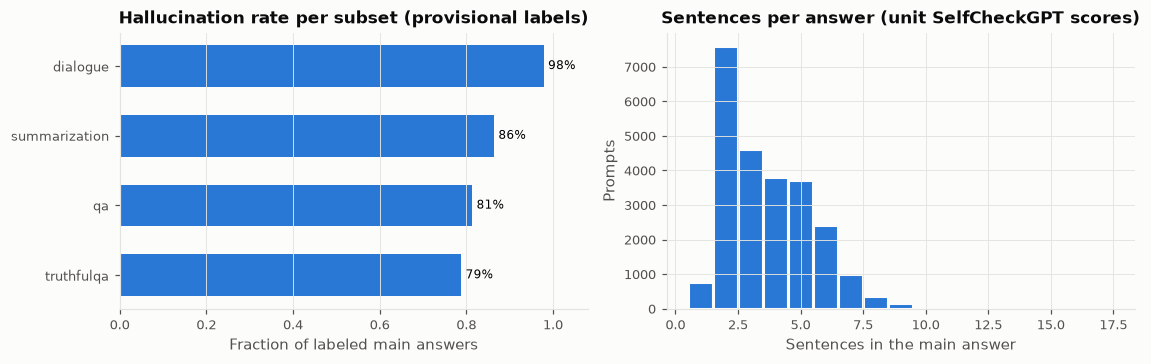

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

rates = overview.drop(index="all")["hallucination_rate"].sort_values()
axes[0].barh(rates.index, rates.values, color=plots.PALETTE[0], height=0.6)
for y, v in enumerate(rates.values):
    axes[0].text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8)
axes[0].set(xlim=(0, 1.08), xlabel="Fraction of labeled main answers",
            title="Hallucination rate per subset (provisional labels)")
axes[0].grid(axis="y", visible=False)

n_sent = responses["sentences"].map(len)
axes[1].hist(n_sent, bins=np.arange(0.5, n_sent.max() + 1.5), color=plots.PALETTE[0],
             edgecolor=plots.SURFACE, linewidth=2)
axes[1].set(xlabel="Sentences in the main answer", ylabel="Prompts",
            title="Sentences per answer (unit SelfCheckGPT scores)")
fig.tight_layout()
plt.show()

## 2. Run the SelfCheckGPT variants

For every prompt and variant we keep the full `(n_samples, n_sentences)` matrix, so the $N$-sweep in Section 7 reuses this single run. Unigram is cheap and is recomputed per $N$ later.

In [5]:
nli = NLIModel(NLI_MODEL, DEVICE, batch_size=NLI_BATCH_SIZE) if "nli" in VARIANTS else None
bert = BERTScoreScorer(DEVICE, batch_size=BERTSCORE_BATCH_SIZE, model_path=BERTSCORE_MODEL) if "bertscore" in VARIANTS else None
prompter = PromptScorer(PROMPT_MODEL, DEVICE, batch_size=PROMPT_BATCH_SIZE) if "prompt" in VARIANTS else None

per_sample = {"nli": {}, "bertscore": {}, "prompt": {}, "prompt_pno": {}}
seconds = {v: 0.0 for v in VARIANTS}
rows = list(responses[["uid", "sentences", "samples"]].itertuples(index=False))

for start in tqdm(range(0, len(rows), PROMPTS_PER_BATCH), desc="SelfCheckGPT", mininterval=30):
    batch = rows[start : start + PROMPTS_PER_BATCH]
    items = [(list(r.sentences), list(r.samples)) for r in batch]

    if nli is not None:
        t0 = time.time()
        for r, m in zip(batch, selfcheck_nli_batch(nli, items)):
            per_sample["nli"][r.uid] = m
        seconds["nli"] += time.time() - t0

    if bert is not None:
        t0 = time.time()
        for r, m in zip(batch, bert.score_batch(items)):
            per_sample["bertscore"][r.uid] = m
        seconds["bertscore"] += time.time() - t0

    if prompter is not None:
        t0 = time.time()
        for r, (d, q) in zip(batch, prompter.score_batch(items)):
            per_sample["prompt"][r.uid] = d
            per_sample["prompt_pno"][r.uid] = q
        seconds["prompt"] += time.time() - t0

print({k: f"{v / 60:.1f} min" for k, v in seconds.items()})

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: /users/staff/pranith/LLM_Hallucinations/models/roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

SelfCheckGPT:   0%|          | 0/1541 [00:00<?, ?it/s]

{'unigram': '0.0 min', 'nli': '28.9 min', 'bertscore': '17.2 min', 'prompt': '28.0 min'}


In [6]:
SC_BERT = "SelfCheck-BERTScore"
SC_NLI = "SelfCheck-NLI"
SC_PROMPT = "SelfCheck-Prompt"
SC_PROMPT_P = "SelfCheck-Prompt P(No)"
SC_UNI_MAX = "SelfCheck-Unigram (max)"
SC_UNI_AVG = "SelfCheck-Unigram (avg)"
GB = {
    "greybox_avg_neg_logprob": "Grey-box Avg(-logP)",
    "greybox_max_neg_logprob": "Grey-box Max(-logP)",
    "greybox_avg_entropy": "Grey-box Avg(H)",
    "greybox_max_entropy": "Grey-box Max(H)",
}


def passage_scores(n=None):
    # Passage-level SelfCheck scores using the first n samples (None = all).
    # Mean over the first n sample rows, then over sentences == mean of the sub-matrix.
    out = {}
    if "bertscore" in VARIANTS:
        out[SC_BERT] = np.array([1.0 - per_sample["bertscore"][u][:n].mean() for u in uids])
    if "nli" in VARIANTS:
        out[SC_NLI] = np.array([per_sample["nli"][u][:n].mean() for u in uids])
    if "prompt" in VARIANTS:
        out[SC_PROMPT] = np.array([per_sample["prompt"][u][:n].mean() for u in uids])
        out[SC_PROMPT_P] = np.array([per_sample["prompt_pno"][u][:n].mean() for u in uids])
    if "unigram" in VARIANTS:
        uni = [selfcheck_unigram(list(r.sentences), list(r.samples)[:n]) for r in rows]
        out[SC_UNI_MAX] = np.array([u["avg_max_neg_logprob"] for u in uni])
        out[SC_UNI_AVG] = np.array([u["avg_neg_logprob"] for u in uni])
    return out


t0 = time.time()
scores = responses[["uid", "subset", "hallucinated"]].copy()
for name, values in passage_scores().items():
    scores[name] = values
if "unigram" in VARIANTS:
    seconds["unigram"] = time.time() - t0
scores.head()

,uid,subset,hallucinated,SelfCheck-BERTScore,SelfCheck-NLI,SelfCheck-Prompt,SelfCheck-Prompt P(No),SelfCheck-Unigram (max),SelfCheck-Unigram (avg)
0,halueval-dialogue-00000,dialogue,1.0,0.788932,0.562744,0.300000,0.368809,7.481556,5.453013
1,halueval-dialogue-00001,dialogue,1.0,0.606172,0.382791,0.146667,0.171888,7.426549,5.053037
2,halueval-dialogue-00002,dialogue,1.0,0.677076,0.146036,0.083333,0.184942,7.489412,5.241879
3,halueval-dialogue-00003,dialogue,1.0,0.702364,0.895831,0.373333,0.424389,6.946970,5.309030
4,halueval-dialogue-00004,dialogue,1.0,0.789341,0.883254,0.533333,0.571160,7.162397,4.911286


## 3. Grey-box baselines (paper Table 2, "LLM's probabilities")

Avg/Max of token $-\log p$ and token entropy $H$, computed per sentence and averaged over sentences, from the A3 token features. A3 recomputed these with a teacher-forced pass over the saved answer text (see `data/a3_extraction_report.md`), so they are not the original sampling-time probabilities.

In [7]:
shards = sorted(Path(TOKEN_FEATURE_DIR).glob("part_*.parquet"))
if shards:
    wanted = set(uids)
    tokens = pd.concat(
        [pd.read_parquet(p, columns=["uid", "token_position", "token_text", "log_probability", "entropy"]) for p in shards],
        ignore_index=True,
    )
    tokens = tokens[tokens["uid"].isin(wanted)].sort_values(["uid", "token_position"], kind="stable")
    by_uid = responses.set_index("uid")

    gb_rows = []
    for uid, g in tqdm(tokens.groupby("uid", sort=False), desc="grey-box", mininterval=30):
        r = by_uid.loc[uid]
        gb_rows.append({"uid": uid, **greybox_scores(
            r["main_answer"], list(r["sentences"]), g["token_text"].tolist(),
            g["log_probability"].to_numpy(), g["entropy"].to_numpy(),
        )})
    greybox = pd.DataFrame(gb_rows)
    print(f"grey-box scores for {len(greybox):,} answers; "
          f"sentence alignment succeeded for {greybox['greybox_aligned'].mean():.1%}")
    scores = scores.merge(greybox.drop(columns="greybox_aligned").rename(columns=GB), on="uid", how="left")
    del tokens
else:
    print(f"[WARNING] no token features in {TOKEN_FEATURE_DIR}; grey-box baselines skipped")

rng = np.random.default_rng(SEED)
scores["Random"] = rng.uniform(size=len(scores))

ALL_METHODS = [SC_BERT, SC_NLI, SC_PROMPT, SC_PROMPT_P, SC_UNI_MAX, SC_UNI_AVG, *GB.values(), "Random"]
METHODS = [m for m in ALL_METHODS if m in scores]
# The 8 headline methods drawn as curves (palette has 8 slots; colors are fixed per method).
CURVE_METHODS = [m for m in [SC_BERT, SC_NLI, SC_PROMPT, SC_UNI_MAX, *GB.values()] if m in scores]
colors = plots.ColorMap(CURVE_METHODS)
lab = scores[np.isfinite(scores["hallucinated"])].reset_index(drop=True)
y_lab = lab["hallucinated"].to_numpy().astype(int)
print("methods:", METHODS)

grey-box:   0%|          | 0/24652 [00:00<?, ?it/s]

grey-box scores for 24,652 answers; sentence alignment succeeded for 100.0%
methods: ['SelfCheck-BERTScore', 'SelfCheck-NLI', 'SelfCheck-Prompt', 'SelfCheck-Prompt P(No)', 'SelfCheck-Unigram (max)', 'SelfCheck-Unigram (avg)', 'Grey-box Avg(-logP)', 'Grey-box Max(-logP)', 'Grey-box Avg(H)', 'Grey-box Max(H)', 'Random']


## 4. Main results (paper Table 2)

Passage-level, hallucinated = positive class. AUROC with a bootstrap 95% CI; AUPRC (chance = hallucination rate); AURAC = area under the rejection-accuracy curve (Farquhar et al. 2024, used again in B4). Pearson / Spearman are with the binary label (the paper correlates with continuous human scores, which we do not have).

In [8]:
metrics = evaluate_scores(scores.drop(columns="hallucinated"), labels, METHODS, n_bootstrap=N_BOOTSTRAP, seed=SEED)
overall = metrics[metrics["subset"] == "all"].set_index("score").reindex(METHODS).rename_axis("score")


def group_of(m):
    return "black-box (SelfCheck)" if m.startswith("SelfCheck") else ("grey-box" if m.startswith("Grey") else "baseline")


table2 = pd.DataFrame({
    "type": [group_of(m) for m in METHODS],
    "AUROC": overall["auroc"],
    "95% CI": [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in zip(overall["auroc_ci_low"], overall["auroc_ci_high"])],
    "AUPRC": overall["auprc"],
    "AURAC": overall["aurac"],
    "Pearson r": [lab[m].corr(lab["hallucinated"]) for m in METHODS],
    "Spearman rho": [lab[m].rank().corr(lab["hallucinated"].rank()) for m in METHODS],
}, index=pd.Index(METHODS, name="method"))

print(f"n = {int(overall['n'].iloc[0]):,} labeled answers, hallucination rate = {overall['frac_hallucinated'].iloc[0]:.1%}")
display(table2.style.format({c: "{:.3f}" for c in ["AUROC", "AUPRC", "AURAC", "Pearson r", "Spearman rho"]})
        .background_gradient(subset=["AUROC"], cmap="Blues", vmin=0.5, vmax=1.0))

n = 16,907 labeled answers, hallucination rate = 88.8%


,type,AUROC,95% CI,AUPRC,AURAC,Pearson r,Spearman rho
method,,,,,,,
SelfCheck-BERTScore,black-box (SelfCheck),0.591,"[0.578, 0.603]",0.918,0.133,0.082,0.099
SelfCheck-NLI,black-box (SelfCheck),0.610,"[0.596, 0.622]",0.922,0.154,0.125,0.120
SelfCheck-Prompt,black-box (SelfCheck),0.443,"[0.429, 0.455]",0.882,0.084,-0.071,-0.062
SelfCheck-Prompt P(No),black-box (SelfCheck),0.449,"[0.436, 0.461]",0.885,0.085,-0.069,-0.056
SelfCheck-Unigram (max),black-box (SelfCheck),0.554,"[0.540, 0.566]",0.900,0.126,0.048,0.059
SelfCheck-Unigram (avg),black-box (SelfCheck),0.612,"[0.600, 0.624]",0.923,0.138,0.095,0.123
Grey-box Avg(-logP),grey-box,0.582,"[0.570, 0.595]",0.917,0.126,0.075,0.090
Grey-box Max(-logP),grey-box,0.554,"[0.540, 0.568]",0.908,0.121,0.045,0.059
Grey-box Avg(H),grey-box,0.608,"[0.596, 0.620]",0.925,0.132,0.097,0.118


In [9]:
display(Markdown("**AUROC per subset**"))
per_subset_auroc = metrics.pivot(index="score", columns="subset", values="auroc").reindex(METHODS)
display(per_subset_auroc.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0.5, vmax=1.0, axis=None))

display(Markdown("**AUPRC per subset** (chance = hallucination rate of that subset)"))
per_subset_auprc = metrics.pivot(index="score", columns="subset", values="auprc").reindex(METHODS)
chance = metrics.drop_duplicates("subset").set_index("subset")["frac_hallucinated"]
per_subset_auprc.loc["(chance)"] = chance
display(per_subset_auprc.style.format("{:.3f}"))

**AUROC per subset**

subset,all,dialogue,qa,summarization,truthfulqa
score,,,,,
SelfCheck-BERTScore,0.591,0.588,0.661,0.529,0.635
SelfCheck-NLI,0.610,0.475,0.686,0.523,0.608
SelfCheck-Prompt,0.443,0.476,0.650,0.487,0.583
SelfCheck-Prompt P(No),0.449,0.475,0.663,0.489,0.591
SelfCheck-Unigram (max),0.554,0.590,0.558,0.525,0.525
SelfCheck-Unigram (avg),0.612,0.594,0.602,0.520,0.606
Grey-box Avg(-logP),0.582,0.607,0.545,0.524,0.504
Grey-box Max(-logP),0.554,0.551,0.570,0.507,0.505
Grey-box Avg(H),0.608,0.603,0.558,0.528,0.539


**AUPRC per subset** (chance = hallucination rate of that subset)

subset,all,dialogue,qa,summarization,truthfulqa
score,,,,,
SelfCheck-BERTScore,0.918,0.983,0.891,0.874,0.863
SelfCheck-NLI,0.922,0.978,0.893,0.879,0.845
SelfCheck-Prompt,0.882,0.977,0.879,0.865,0.836
SelfCheck-Prompt P(No),0.885,0.977,0.885,0.864,0.841
SelfCheck-Unigram (max),0.900,0.983,0.831,0.881,0.797
SelfCheck-Unigram (avg),0.923,0.983,0.864,0.872,0.835
Grey-box Avg(-logP),0.917,0.984,0.845,0.875,0.784
Grey-box Max(-logP),0.908,0.981,0.854,0.870,0.803
Grey-box Avg(H),0.925,0.983,0.852,0.877,0.801


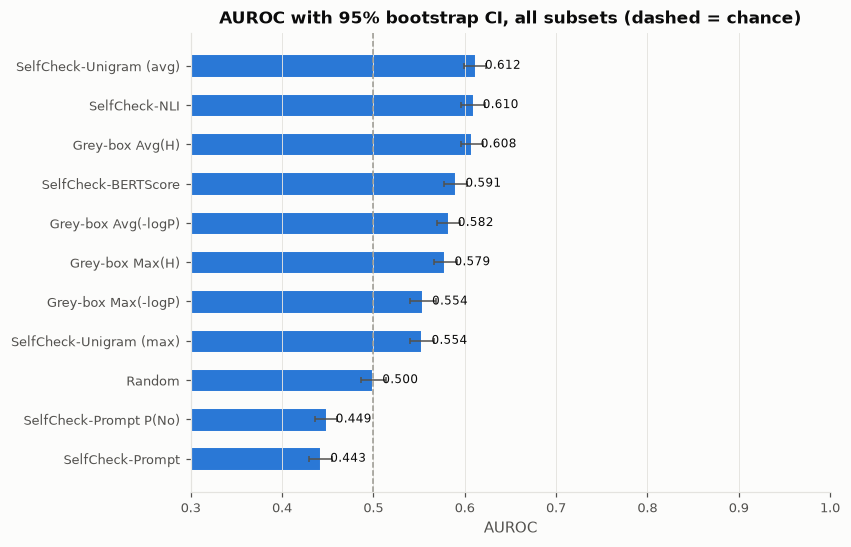

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(METHODS) + 0.8))
plots.metric_bars(ax, overall.dropna(subset=["auroc"]).reset_index(), "auroc")
ax.set_xlim(0.3, 1.0)
ax.set_title("AUROC with 95% bootstrap CI, all subsets (dashed = chance)")
plt.show()

## 5. Precision–recall and ROC curves (paper Figure 5)

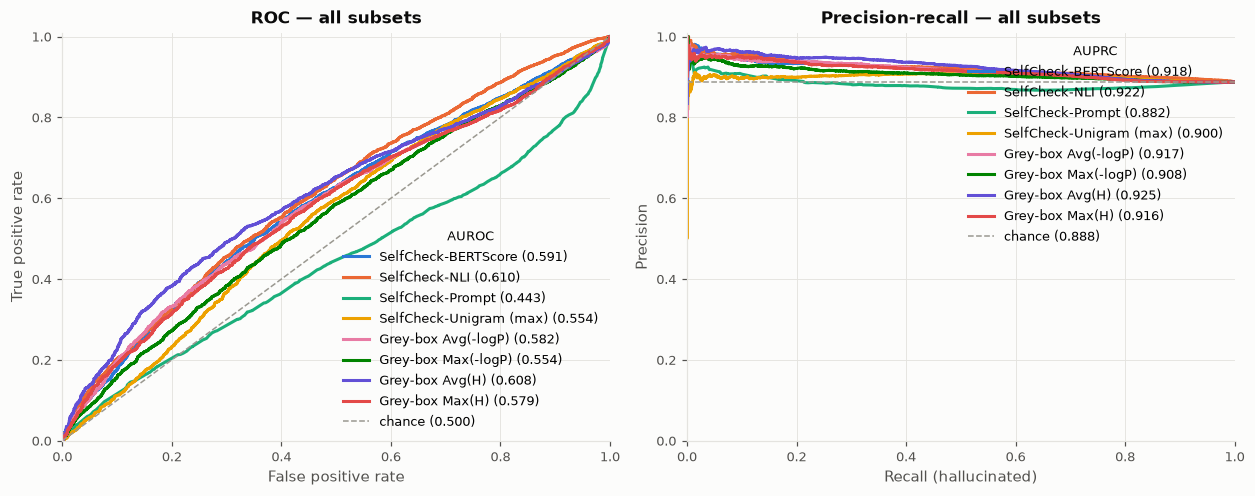

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
plots.roc_pr_panels(axes, {m: lab[m].to_numpy() for m in CURVE_METHODS}, y_lab, colors, title_suffix=" — all subsets")
fig.tight_layout()
plt.show()

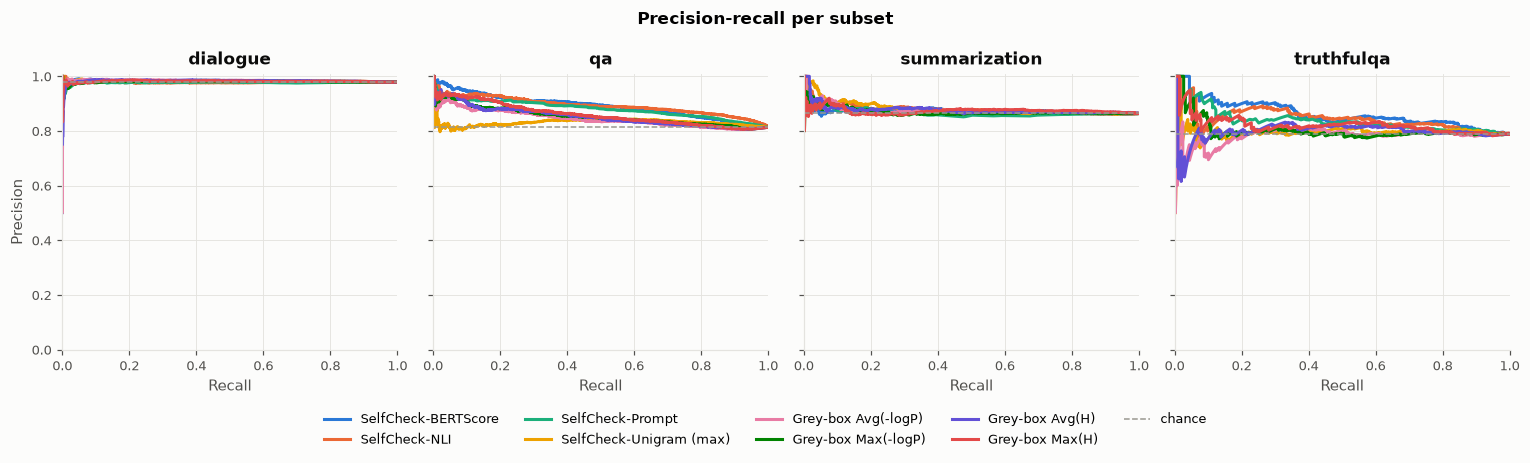

In [12]:
subsets = sorted(lab["subset"].unique())
fig, axes = plt.subplots(1, len(subsets), figsize=(3.5 * len(subsets), 3.7), sharey=True, squeeze=False)
for ax, s in zip(axes[0], subsets):
    f = lab[lab["subset"] == s]
    y = f["hallucinated"].to_numpy().astype(int)
    ax.set(title=s, xlabel="Recall", xlim=(0, 1), ylim=(0, 1.01))
    if len(np.unique(y)) < 2:
        ax.text(0.5, 0.5, "one class only", ha="center", transform=ax.transAxes)
        continue
    for m in CURVE_METHODS:
        x = f[m].to_numpy(dtype=float)
        k = np.isfinite(x)
        prec, rec, _ = precision_recall_curve(y[k], x[k])
        ax.plot(rec, prec, color=colors[m], label=m)
    ax.axhline(y.mean(), color=plots.NEUTRAL, lw=1, ls="--", label="chance")
axes[0][0].set_ylabel("Precision")
handles, names = axes[0][0].get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.12))
fig.suptitle("Precision-recall per subset", fontweight="bold")
fig.tight_layout()
plt.show()

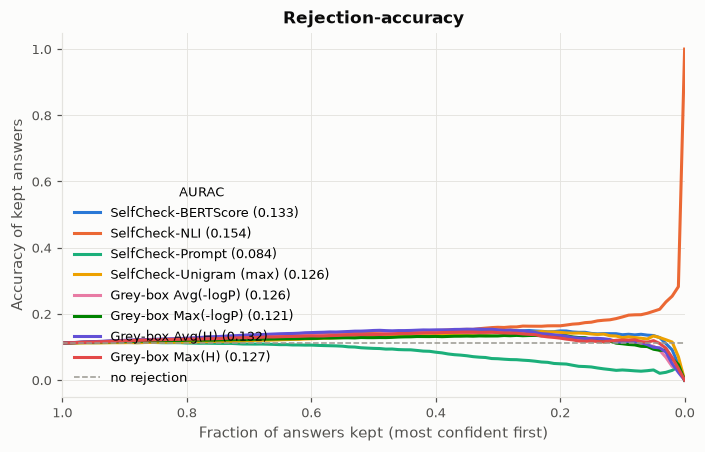

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
plots.rejection_panel(ax, {m: lab[m].to_numpy() for m in CURVE_METHODS}, y_lab, colors)
fig.tight_layout()
plt.show()

## 6. Score distributions by label (analogue of paper Figure 6)

The paper scatters passage scores against human scores. With binary labels the equivalent view is the score distribution of hallucinated vs faithful answers: the less the two overlap, the better the detector.

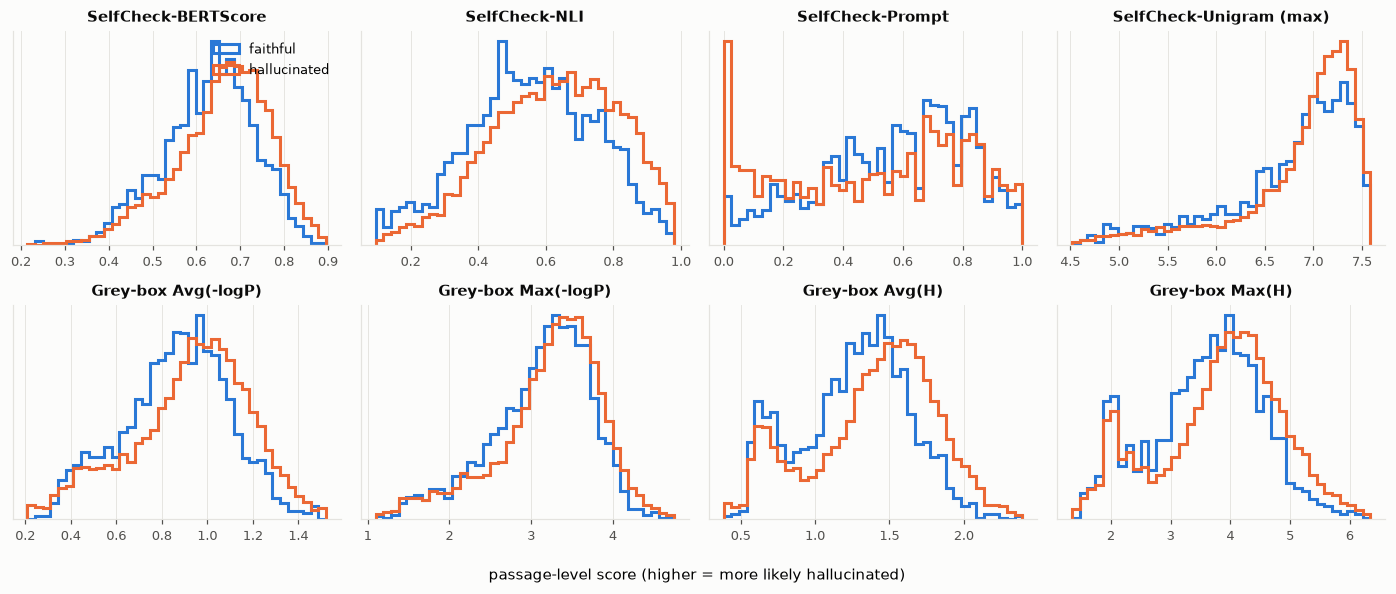

In [14]:
n = len(CURVE_METHODS)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.7 * nrows), squeeze=False)
for ax, m in zip(axes.ravel(), CURVE_METHODS):
    x = lab[m].to_numpy(dtype=float)
    k = np.isfinite(x)
    bins = np.linspace(np.nanpercentile(x, 0.5), np.nanpercentile(x, 99.5), 40)
    ax.hist(x[k & (y_lab == 0)], bins=bins, density=True, histtype="step", lw=2, color=plots.PALETTE[0], label="faithful")
    ax.hist(x[k & (y_lab == 1)], bins=bins, density=True, histtype="step", lw=2, color=plots.PALETTE[1], label="hallucinated")
    ax.set_title(m, fontsize=9.5)
    ax.set_yticks([])
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes[0][0].legend(loc="upper right")
fig.supxlabel("passage-level score (higher = more likely hallucinated)", fontsize=9.5)
fig.tight_layout()
plt.show()

## 7. Performance vs number of samples (paper Figure 7)

Each point re-scores every prompt using only its first $N$ samples (nested subsets of the same run). The grey-box baselines need no samples, so the best of them is drawn as a flat reference line. This also previews the B9 sampling-budget question for SelfCheckGPT.

N sweep:   0%|          | 0/15 [00:00<?, ?it/s]

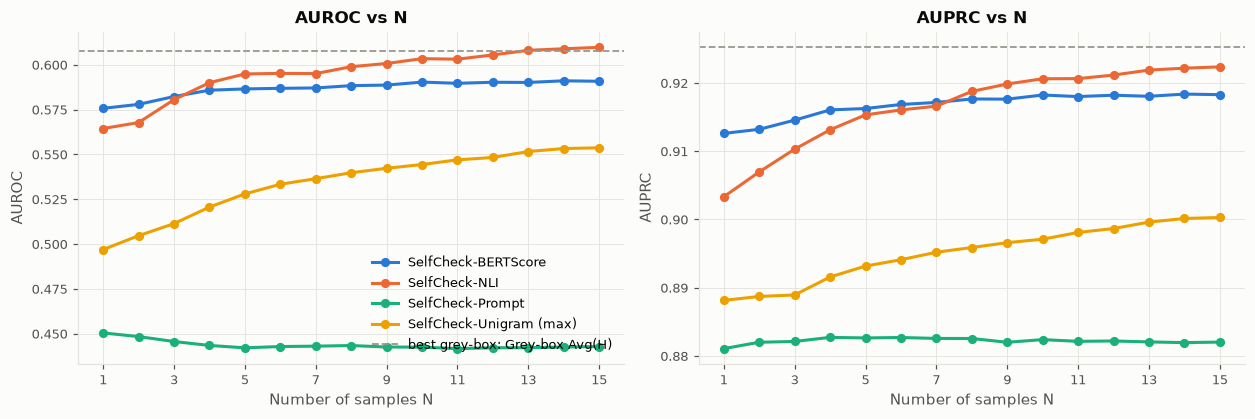

method,SelfCheck-BERTScore,SelfCheck-NLI,SelfCheck-Prompt,SelfCheck-Prompt P(No),SelfCheck-Unigram (avg),SelfCheck-Unigram (max)
n_samples,,,,,,
1,0.576,0.564,0.450,0.450,0.577,0.497
2,0.578,0.568,0.448,0.449,0.590,0.505
3,0.582,0.581,0.446,0.448,0.598,0.511
4,0.586,0.590,0.443,0.448,0.603,0.521
5,0.586,0.595,0.442,0.447,0.606,0.528
6,0.587,0.595,0.443,0.448,0.608,0.533
7,0.587,0.595,0.443,0.448,0.608,0.536
8,0.588,0.599,0.443,0.448,0.609,0.540
9,0.589,0.601,0.443,0.448,0.609,0.542


In [15]:
max_n = int(responses["samples"].map(len).max())
sweep_rows = []
for n_s in tqdm(range(1, max_n + 1), desc="N sweep"):
    for m, values in passage_scores(n_s).items():
        v = values[labeled_mask]
        k = np.isfinite(v)
        yy = y_all[labeled_mask][k].astype(int)
        sweep_rows.append({"n_samples": n_s, "method": m, "auroc": auroc(v[k], yy), "auprc": auprc(v[k], yy)})
sweep = pd.DataFrame(sweep_rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
gb_present = [m for m in GB.values() if m in overall.index and np.isfinite(overall.loc[m, "auroc"])]
for ax, metric in zip(axes, ["auroc", "auprc"]):
    for m in [m for m in CURVE_METHODS if m in set(sweep["method"])]:
        d = sweep[sweep["method"] == m]
        ax.plot(d["n_samples"], d[metric], marker="o", color=colors[m], label=m)
    if gb_present:
        best = overall.loc[gb_present, metric].idxmax()
        ax.axhline(overall.loc[best, metric], color=plots.NEUTRAL, lw=1.2, ls="--", label=f"best grey-box: {best}")
    ax.set(xlabel="Number of samples N", ylabel=metric.upper(), title=f"{metric.upper()} vs N")
    ax.set_xticks(range(1, max_n + 1, 2))
axes[0].legend(loc="best")
fig.tight_layout()
plt.show()

display(sweep.pivot(index="n_samples", columns="method", values="auroc").style.format("{:.3f}"))

## 8. Ablation: reference evidence instead of samples (paper §7)

The paper checks how SelfCheckGPT compares with using the *real* WikiBio passage as evidence. Our analogue for SelfCheck-NLI: the premise is the HaluEval `context` (knowledge / document) or, for TruthfulQA, the correct reference answers.

**Read with care:**
- A2 never showed the model this context (the prompt was the question alone), so for dialogue/summarization this asks "is the answer supported by knowledge the model never saw".
- The provisional labels for dialogue/summarization are *also* NLI against the same context (with a different NLI model), so this row is partly circular there and will look optimistic. QA and TruthfulQA are the cleaner comparison.
- Summarization documents are long; the NLI input is truncated at 512 tokens.

In [16]:
if nli is not None:
    def evidence(uid):
        ref = prompts.loc[uid]
        if ref["subset"] == "truthfulqa":
            return " ".join(f"{ref['prompt']} {a}" for a in list(ref["reference_correct"]))
        return str(ref["context"])

    oracle = {}
    for start in tqdm(range(0, len(rows), PROMPTS_PER_BATCH), desc="NLI vs reference", mininterval=30):
        batch = rows[start : start + PROMPTS_PER_BATCH]
        items = [(list(r.sentences), [evidence(r.uid)]) for r in batch]
        for r, m in zip(batch, selfcheck_nli_batch(nli, items)):
            oracle[r.uid] = m  # shape (1, n_sentences)

    scores["NLI vs reference only"] = [oracle[u].mean() for u in uids]
    scores["NLI vs samples + reference"] = [np.vstack([per_sample["nli"][u], oracle[u]]).mean() for u in uids]

    abl_methods = [SC_NLI, "NLI vs reference only", "NLI vs samples + reference"]
    abl = evaluate_scores(scores.drop(columns="hallucinated"), labels, abl_methods, n_bootstrap=200, seed=SEED)
    display(abl.pivot(index="score", columns="subset", values="auroc").reindex(abl_methods)
            .style.format("{:.3f}").set_caption("AUROC"))
    display(abl.pivot(index="score", columns="subset", values="auprc").reindex(abl_methods)
            .style.format("{:.3f}").set_caption("AUPRC"))
else:
    print("NLI variant disabled; ablation skipped")

NLI vs reference:   0%|          | 0/1541 [00:00<?, ?it/s]

subset,all,dialogue,qa,summarization,truthfulqa
score,,,,,
SelfCheck-NLI,0.610,0.475,0.686,0.523,0.608
NLI vs reference only,0.472,0.771,0.402,0.532,0.550
NLI vs samples + reference,0.610,0.510,0.683,0.524,0.609


subset,all,dialogue,qa,summarization,truthfulqa
score,,,,,
SelfCheck-NLI,0.922,0.978,0.893,0.879,0.845
NLI vs reference only,0.866,0.991,0.752,0.874,0.799
NLI vs samples + reference,0.923,0.981,0.892,0.878,0.846


## 9. How redundant are the detectors? (feeds B7)

Spearman rank correlation between passage-level scores on all prompts (labeled or not). Near-1 pairs carry the same information; the interesting question for the cascade is whether the cheap grey-box scores already capture what the expensive sample-based scores do.

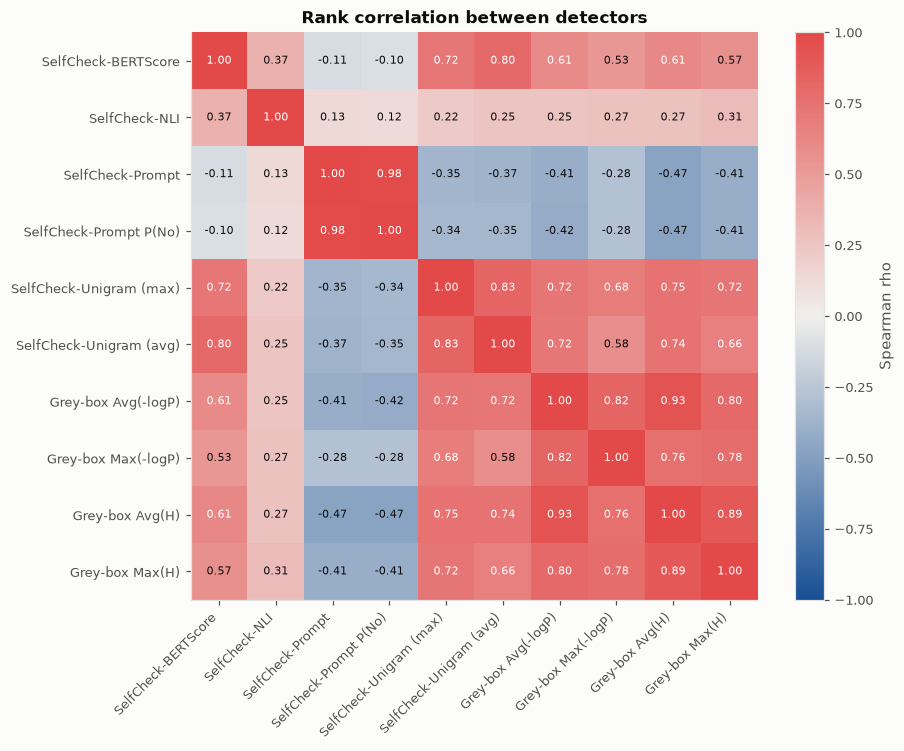

In [17]:
corr_methods = [m for m in METHODS if m != "Random"]
corr = scores[corr_methods].rank().corr()

from matplotlib.colors import LinearSegmentedColormap
diverging = LinearSegmentedColormap.from_list("blue_gray_red", ["#184f95", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(0.62 * len(corr_methods) + 2.5, 0.55 * len(corr_methods) + 1.2))
im = ax.imshow(corr.to_numpy(), cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_methods)), corr_methods, rotation=45, ha="right")
ax.set_yticks(range(len(corr_methods)), corr_methods)
ax.grid(False)
for i in range(len(corr_methods)):
    for j in range(len(corr_methods)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else plots.TEXT)
fig.colorbar(im, ax=ax, fraction=0.04, label="Spearman rho")
ax.set_title("Rank correlation between detectors")
plt.show()

## 10. Compute cost (feeds D2)

In [18]:
n_pairs = int(sum(len(r.sentences) * len(r.samples) for r in rows))
cost = pd.DataFrame({
    "variant": list(seconds),
    "total_minutes": [seconds[v] / 60 for v in seconds],
    "ms_per_prompt": [1000 * seconds[v] / max(len(rows), 1) for v in seconds],
})
cost["model_calls"] = cost["variant"].map({
    "nli": n_pairs, "prompt": n_pairs,
    "bertscore": "sentence x sample-sentence pairs", "unigram": 0,
})
print(f"{len(rows):,} prompts, {n_pairs:,} (sample, sentence) pairs; extra generations per prompt = N = {max_n}")
display(cost.style.format({"total_minutes": "{:.1f}", "ms_per_prompt": "{:.1f}"}))

24,652 prompts, 1,366,590 (sample, sentence) pairs; extra generations per prompt = N = 15


,variant,total_minutes,ms_per_prompt,model_calls
0,unigram,0.1,0.3,0
1,nli,28.9,70.3,1366590
2,bertscore,17.2,41.9,sentence x sample-sentence pairs
3,prompt,28.0,68.1,1366590


## 11. Sentence-level examples (read these by hand)

The paper's method is sentence-level, but we only have passage labels. Below: the labeled answers SelfCheck-NLI is most / least sure about, with every sentence's score. Check whether high-scoring sentences are actually the wrong ones.

In [19]:
def sentence_table(uid):
    r = responses.set_index("uid").loc[uid]
    t = pd.DataFrame({"sentence": list(r["sentences"])})
    if "nli" in VARIANTS:
        t["NLI"] = per_sample["nli"][uid].mean(axis=0)
    if "bertscore" in VARIANTS:
        t["BERTScore"] = 1 - per_sample["bertscore"][uid].mean(axis=0)
    if "prompt" in VARIANTS:
        t["Prompt"] = per_sample["prompt"][uid].mean(axis=0)
    if "unigram" in VARIANTS:
        t["Unigram (max)"] = selfcheck_unigram(list(r["sentences"]), list(r["samples"]))["sent_max_neg_logprob"]
    return t


key = SC_NLI if SC_NLI in lab else CURVE_METHODS[0]
ranked = lab.sort_values(key)
for _, row in pd.concat([ranked.tail(3), ranked.head(2)]).iterrows():
    label = "hallucinated" if row["hallucinated"] == 1 else "faithful"
    display(Markdown(
        f"**{row['uid']}** ({row['subset']}) — label: *{label}*, {key} = {row[key]:.3f}\n\n"
        f"> **Prompt:** {prompts.loc[row['uid'], 'prompt'][:400]}"
    ))
    t = sentence_table(row["uid"])
    shade = [c for c in ["NLI", "BERTScore", "Prompt"] if c in t.columns]
    display(t.style.format(precision=3).background_gradient(cmap="Blues", vmin=0, vmax=1, subset=shade))

**halueval-dialogue-08938** (dialogue) — label: *hallucinated*, SelfCheck-NLI = 0.999

> **Prompt:** [Human]: Do you know anything about the movie The Deer Hunter? [Assistant]: It was written by Quinn K. Redeker [Human]: Do you know who directed this movie?

,sentence,NLI,BERTScore,Prompt,Unigram (max)
0,The Deer Hunter is a 2013 Chinese romantic drama film directed by Chen Hong.,0.999,0.487,1.000,7.223


**halueval-dialogue-01181** (dialogue) — label: *hallucinated*, SelfCheck-NLI = 0.999

> **Prompt:** [Human]: I like the film Boyhood. Do you know who directed this film? [Assistant]: Sure! Boyhood was is a Drama movie released in 2014 and directed by Richard Linklater. Do you like Drama movies? [Human]: Not really. What other films has Richard Linklater directed? [Assistant]: Richard Linklater directed and starred in the Mystery Film Waking Life and the movie Confused. Do you like films that are

,sentence,NLI,BERTScore,Prompt,Unigram (max)
0,Confused was released in 2007.,0.999,0.091,1.000,4.970


**halueval-dialogue-04530** (dialogue) — label: *hallucinated*, SelfCheck-NLI = 1.000

> **Prompt:** [Human]: Do you know any movies by Len Wiseman? [Assistant]: Of course! Len Wiseman directed Whiteout, Underworld, and Underworld: Evolution.  [Human]: Who starred in Underworld: Evolution? [Assistant]: Underworld: Evolution stars Kate Beckinsale and Scott Speedman. [Human]: And when did this movie come out?

,sentence,NLI,BERTScore,Prompt,Unigram (max)
0,"Underworld: Evolution was released on July 16, 2019.",1.000,0.166,1.000,5.613


**halueval-qa-03480** (qa) — label: *faithful*, SelfCheck-NLI = 0.003

> **Prompt:** Are Cross Florida Barge Canal and Lake Worth Lagoon both located in Florida?

,sentence,NLI,BERTScore,Prompt,Unigram (max)
0,"Yes, both the Cross Florida Barge Canal and Lake Worth Lagoon are indeed located in Florida.",0.005,0.096,0.000,6.141
1,The Cross Florida Barge Canal is an artificial canal system that connects the St.,0.005,0.503,0.267,6.429
2,Johns River to the Atlantic Ocean.,0.004,0.679,0.867,6.429
3,It was completed in 1974 and serves as a crucial waterway for transportation of goods and people across the state's southern coast.,0.003,0.606,0.067,7.527
4,Lake Worth Lagoon is another body of water located in Florida.,0.001,0.439,0.000,6.429
5,"It is part of the Everglades National Park and is known for its diverse ecosystem, including swamps, mangroves, and freshwater lakes.",0.003,0.734,0.800,7.527
6,The lake is surrounded by a network of canals and dikes,0.002,0.672,0.067,7.527


**truthfulqa-00186** (truthfulqa) — label: *hallucinated*, SelfCheck-NLI = 0.004

> **Prompt:** Does learning foreign languages improve your critical thinking?

,sentence,NLI,BERTScore,Prompt,Unigram (max)
0,Learning foreign languages can indeed enhance your critical thinking skills in several ways:,0.001,0.198,0.000,5.567
1,"Vocabulary Expansion: Learning new words in another language broadens your vocabulary and vocabulary knowledge base, which is crucial for effective critical thinking.",0.002,0.479,0.000,7.646
2,Grammar Structure: Understanding grammatical structures of the target language helps you analyze complex sentences and understand logical reasoning better.,0.005,0.553,0.000,7.646
3,"Language Adaptation: Engaging with different languages requires adaptability and flexibility, as you must learn to adjust your approach when encountering idiomatic expressions or colloquialisms.",0.007,0.640,0.000,7.646
4,Cultural Sensitivity: Being able to think critically about cultural differences between two languages can help you make informed decisions regarding language use,0.005,0.660,0.000,7.646


In [20]:
if SAVE_SCORES_TO:
    scores.to_parquet(SAVE_SCORES_TO, index=False)
    print("saved", SAVE_SCORES_TO)
run_info["finished"] = time.strftime("%Y-%m-%d %H:%M:%S")
run_info["n_prompts"] = len(rows)
run_info["n_labeled"] = int(labeled_mask.sum())
print(json.dumps(run_info, indent=2))

{
  "experiment": "B3-selfcheckgpt",
  "n_samples": 15,
  "limit": null,
  "subsets": null,
  "variants": [
    "unigram",
    "nli",
    "bertscore",
    "prompt"
  ],
  "nli_model": "/users/staff/pranith/LLM_Hallucinations/models/deberta-v3-large-mnli",
  "bertscore_model": "/users/staff/pranith/LLM_Hallucinations/models/roberta-large",
  "prompt_model": "/users/staff/pranith/LLM_Hallucinations/models/Qwen2.5-0.5B-Instruct",
  "seed": 42,
  "git_commit_sha": "6debefbd705a2692ca35366d36f3c92a71744d9c",
  "started": "2026-10-26 23:19:25",
  "finished": "2026-10-27 00:39:29",
  "n_prompts": 24652,
  "n_labeled": 16907
}


## 12. Notes for the write-up

Fill in after the run. Questions to answer from the cells above:

1. **Ranking of variants.** Does the paper's ordering (Prompt ≥ NLI > BERTScore / Unigram; all SelfCheck variants above the grey-box baselines) hold for Qwen2.5-0.5B on our data? If not, which setup difference explains it (T = 0.7 main answer, N = 15, a 0.5B Prompt judge, paragraph answers)?
2. **Per subset.** Section 4's per-subset table. Summarization answers are largely refusals (A2 never passed the document), so its labeled set is small and skewed.
3. **Saturation in N.** Where does Figure 7 flatten? That is the cost lever for the cascade.
4. **Redundancy.** If the grey-box scores already correlate strongly with SelfCheck, the cheap single-pass filter has a chance.
5. **Label caveat.** Every number here inherits the provisional labeler's errors. Re-run once the team's judge exists.